# Linear regression baseline

**Goal.** Predict the next NVDA close from the previous five closes, and compare the error to "tomorrow equals today."

**Method.** Daily closes from 2020. Lags 1 through 5. First 80% of rows for training, last 20% for testing, in time order. Ordinary least squares. The naive forecast is the previous close (`lag_1`).

**Result.** Model error $3.75 per day. Naive baseline $3.75 per day. The regression learned persistence. It did not improve on guessing that tomorrow's close equals today's.


[*********************100%***********************]  1 of 1 completed


Model error:    $3.75 per day
Naive baseline: $3.75 per day

Next 7 days:
2026-11-26  $145.60
2026-11-27  $144.67
2026-11-30  $145.77
2026-12-01  $146.39
2026-12-02  $146.90
2026-12-03  $147.12
2026-12-04  $147.31


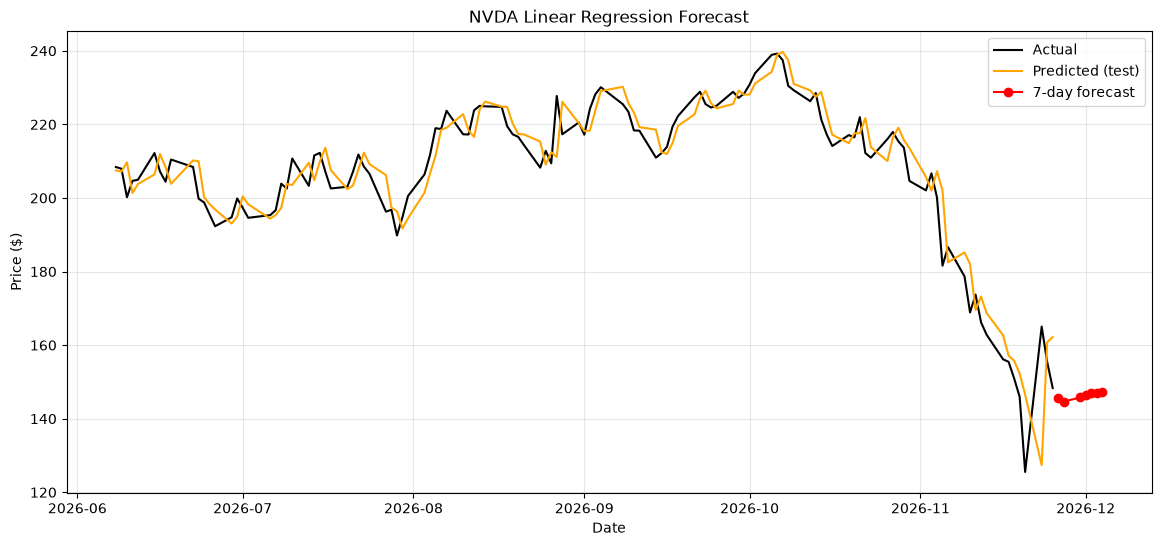

In [1]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

ticker = "NVDA"   # or "NQ=F"
n_lags = 5        # use the last 5 closes to predict the next one
horizon = 7       # days to forecast

# Extract historical data
df = yf.download(ticker, start="2020-01-01", multi_level_index=False)[["Close"]].dropna()

# Features: the previous 5 closing prices
for i in range(1, n_lags + 1):
    df[f"lag_{i}"] = df["Close"].shift(i)
df = df.dropna()

feature_cols = [f"lag_{i}" for i in range(1, n_lags + 1)]
X = df[feature_cols]
y = df["Close"]

# Train/test split: first 80% train, last 20% test (no shuffling with time series)
split = int(len(df) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

# Train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Test the model
pred_test = model.predict(X_test)
mae = mean_absolute_error(y_test, pred_test)
naive_mae = mean_absolute_error(y_test, X_test["lag_1"])  # "tomorrow = today"
print(f"Model error:    ${mae:.2f} per day")
print(f"Naive baseline: ${naive_mae:.2f} per day")

# Forecast the next 7 days (each prediction feeds the next)
history = df["Close"].tolist()
future = []
for _ in range(horizon):
    feats = pd.DataFrame([history[-1:-n_lags - 1:-1]], columns=feature_cols)
    next_close = model.predict(feats)[0]
    future.append(next_close)
    history.append(next_close)

future_dates = pd.bdate_range(df.index[-1] + pd.Timedelta(days=1), periods=horizon)
print("\nNext 7 days:")
for d, v in zip(future_dates, future):
    print(f"{d.date()}  ${v:,.2f}")

# Plot: test period + forecast
plt.figure(figsize=(14, 6))
plt.plot(y_test.index[-120:], y_test[-120:], label="Actual", color="black")
plt.plot(y_test.index[-120:], pred_test[-120:], label="Predicted (test)", color="orange")
plt.plot(future_dates, future, label="7-day forecast", color="red", marker="o")
plt.title(f"{ticker} Linear Regression Forecast")
plt.xlabel("Date")
plt.ylabel("Price ($)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
